# Part 1 — Analysis (executed notebook)

Same engine as `run_analysis.py`: DuckDB SQL from `src/queries.py`, pandas for pivots and an independent cross-check. Money is rounded to the nearest rupee and percentages to one decimal at display time only. The narrative answers are in `Part1_Analysis.md` / `.pdf`; this notebook shows the tables with the code that produced them.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
ROOT = ROOT if (ROOT / 'src').exists() else ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display
from src import analysis as A, queries as Q
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

res = A.run_all(ROOT / 'data' / 'raw')

def show(df, money=(), pct=(), ratio=(), index=False):
    d = df.copy()
    for c in money: d[c] = d[c].map(A.inr)
    for c in pct: d[c] = d[c].map(A.pct)
    for c in ratio: d[c] = d[c].map(A.ratio)
    display(d if index else d.reset_index(drop=True))

## 1. Data quality

Four issues found (duplicate order rows, blank channel, internal test accounts, non-delivered orders) plus the checks that passed. The SQL for each check is printed above its result.

In [2]:
for name in ['duplicate_order_rows', 'conflicting_duplicates', 'blank_channel', 'internal_accounts', 'status_mix', 'passed_checks']:
    print(Q.DQ[name].strip().splitlines()[0].strip())
    display(res.dq[name].round(2))

-- Issue 1: exact duplicate rows in orders (same order_id, every column identical)


,duplicate_rows,raw_rows,distinct_order_ids
0,206,5684,5478


-- Are any duplicated order_ids NOT identical across columns? (0 = safe to dedupe with DISTINCT)


,conflicting_order_ids
0,0


-- Issue 2: users with a blank acquisition_channel, and what they contributed


...

,users,channels,orders,delivered_orders,min_orders_per_user,max_orders_per_user,avg_order_value,avg_order_value_all
0,35,Affiliate,285,285,6,11,2736.11,1168.78


-- Issue 4: non-successful orders (excluded from revenue and customer counts per the brief)


,status,orders_after_dedup
0,delivered,4799
1,returned,364
2,cancelled,315


-- Checks that found nothing (reported so the reader knows they were run)


,orphan_orders,orders_before_signup,null_order_fields,null_user_fields,non_positive_values,duplicate_user_ids,duplicate_emails,distinct_status_values,distinct_channel_values,spend_rows,spend_expected_rows,signups_outside_window,orders_outside_window,min_order_value,max_order_value,users_with_no_orders,total_spend
0,0,0,0,0,0,0,0,3,5,24,24,0,0,199.0,3991.0,2097,1590000.0


**Why the internal accounts matter** — Affiliate with and without the 35 `@urbancart.in` accounts:

In [3]:
print(Q.AFFILIATE_BEFORE_AFTER.strip().splitlines()[0].strip())
show(res.affiliate_before_after, money=['revenue_per_customer', 'cac'], pct=['repeat_rate_pct'], ratio=['ltv_to_cac'])

-- Impact of Issue 3: Affiliate metrics with and without the internal accounts


,version,customers,revenue_per_customer,repeat_rate_pct,cac,ltv_to_cac
0,with internal accounts (naive),540,"₹2,339",14.1%,₹641,1.10
1,without internal accounts (clean),505,₹957,8.1%,₹685,0.42


## 2. Acquisition cost (paid channels)

In [4]:
print(Q.Q2_ACQUISITION_COST)
show(res.q2, money=['spend_inr', 'cac'])


    -- Q2: total spend, new customers and CAC per paid channel (Jan–Jun)
    WITH nc AS (SELECT acquisition_channel AS channel, COUNT(*) AS new_customers FROM customers_clean GROUP BY 1),
         sp AS (SELECT channel, SUM(spend_inr) AS spend_inr FROM spend GROUP BY 1)
    SELECT sp.channel, sp.spend_inr, nc.new_customers, sp.spend_inr / nc.new_customers AS cac
    FROM sp JOIN nc USING (channel)
    ORDER BY cac


,channel,spend_inr,new_customers,cac
0,Google Ads,"₹4,00,000",655,₹611
1,Affiliate,"₹3,46,000",505,₹685
2,Meta Ads,"₹5,47,000",675,₹810
3,Influencer,"₹2,97,000",307,₹967


## 3. Customer value (all channels, including Organic)

In [5]:
print(Q.Q3_CUSTOMER_VALUE)
show(res.q3, money=['revenue', 'revenue_per_customer'], pct=['repeat_rate_pct'])


    -- Q3: revenue per customer and repeat purchase rate per channel, including Organic
    SELECT acquisition_channel AS channel,
           COUNT(*)                                                   AS customers,
           SUM(revenue)                                               AS revenue,
           SUM(revenue) / COUNT(*)                                    AS revenue_per_customer,
           100.0 * COUNT(*) FILTER (WHERE delivered_orders >= 2) / COUNT(*) AS repeat_rate_pct
    FROM customers_clean
    GROUP BY 1
    ORDER BY revenue_per_customer DESC


,channel,customers,revenue,revenue_per_customer,repeat_rate_pct
0,Influencer,307,"₹8,77,469","₹2,858",73.0%
1,Google Ads,655,"₹15,13,880","₹2,311",57.7%
2,Organic,461,"₹8,77,167","₹1,903",55.7%
3,Meta Ads,675,"₹11,24,892","₹1,667",44.7%
4,Affiliate,505,"₹4,83,387",₹957,8.1%


## 4. Return on spend (LTV:CAC)

In [6]:
print(Q.Q4_LTV_CAC.replace('{margin}', str(A.MARGIN)))
show(res.q4, money=['revenue_per_customer', 'ltv', 'cac'], ratio=['ltv_to_cac'])
print(f'Best: {res.q4.iloc[0].channel} ({res.q4.iloc[0].ltv_to_cac:.2f}); worst: {res.q4.iloc[-1].channel} ({res.q4.iloc[-1].ltv_to_cac:.2f})')


    -- Q4: LTV = revenue per customer x 30% contribution margin; LTV:CAC per paid channel
    WITH v AS (SELECT acquisition_channel AS channel, SUM(revenue) / COUNT(*) AS revenue_per_customer
               FROM customers_clean GROUP BY 1),
         sp AS (SELECT channel, SUM(spend_inr) AS spend_inr FROM spend GROUP BY 1),
         nc AS (SELECT acquisition_channel AS channel, COUNT(*) AS new_customers FROM customers_clean GROUP BY 1),
         c  AS (SELECT channel, sp.spend_inr / nc.new_customers AS cac FROM sp JOIN nc USING (channel))
    SELECT v.channel, v.revenue_per_customer, v.revenue_per_customer * 0.3 AS ltv, c.cac,
           (v.revenue_per_customer * 0.3) / c.cac AS ltv_to_cac
    FROM v JOIN c USING (channel)
    ORDER BY ltv_to_cac DESC


,channel,revenue_per_customer,ltv,cac,ltv_to_cac
0,Google Ads,"₹2,311",₹693,₹611,1.14
1,Influencer,"₹2,858",₹857,₹967,0.89
2,Meta Ads,"₹1,667",₹500,₹810,0.62
3,Affiliate,₹957,₹287,₹685,0.42


Best: Google Ads (1.14); worst: Affiliate (0.42)


## 5. Trend — monthly CAC by signup-month cohort


    -- Q5: CAC by month per paid channel; new customers grouped by SIGNUP month
    WITH nc AS (SELECT acquisition_channel AS channel, signup_month AS month, COUNT(*) AS new_customers
                FROM customers_clean GROUP BY 1, 2)
    SELECT s.month, s.channel, s.spend_inr, nc.new_customers, s.spend_inr / nc.new_customers AS cac
    FROM spend s LEFT JOIN nc USING (channel, month)
    ORDER BY s.channel, s.month


month,Jan,Feb,Mar,Apr,May,Jun
channel,,,,,,
Google Ads,₹592,₹621,₹596,₹602,₹644,₹611
Meta Ads,₹491,₹618,₹789,₹886,₹958,"₹1,115"
Affiliate,₹709,₹709,₹728,₹633,₹667,₹682
Influencer,₹981,₹980,₹913,₹960,₹964,"₹1,000"


,channel,cac_jan,cac_jun,abs_change,pct_change,spend_pct_change
0,Meta Ads,₹491,"₹1,115",₹624,127.2%,114.8%
1,Google Ads,₹592,₹611,₹19,3.2%,-25.7%
2,Influencer,₹981,"₹1,000",₹19,2.0%,2.0%
3,Affiliate,₹709,₹682,-₹27,-3.9%,-26.2%


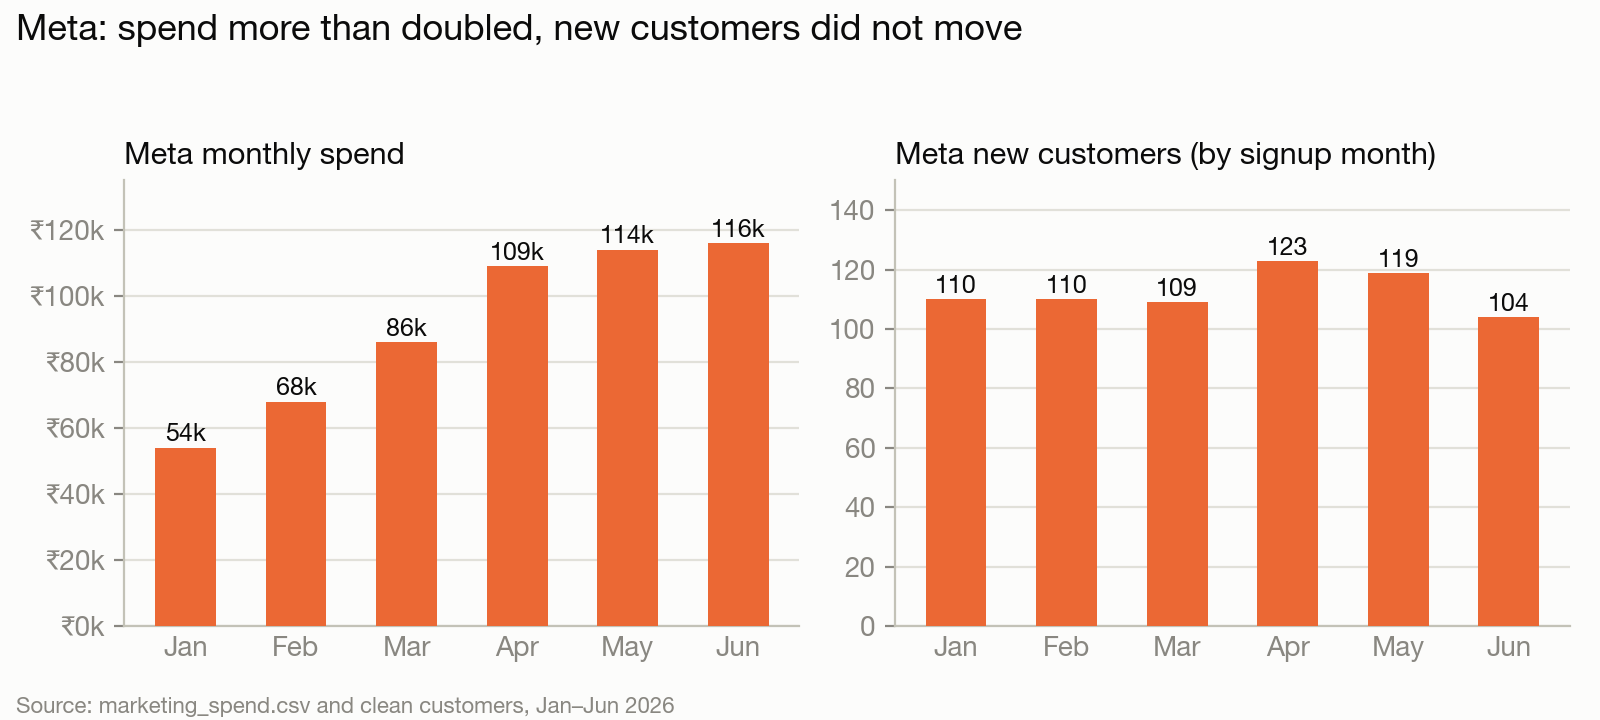

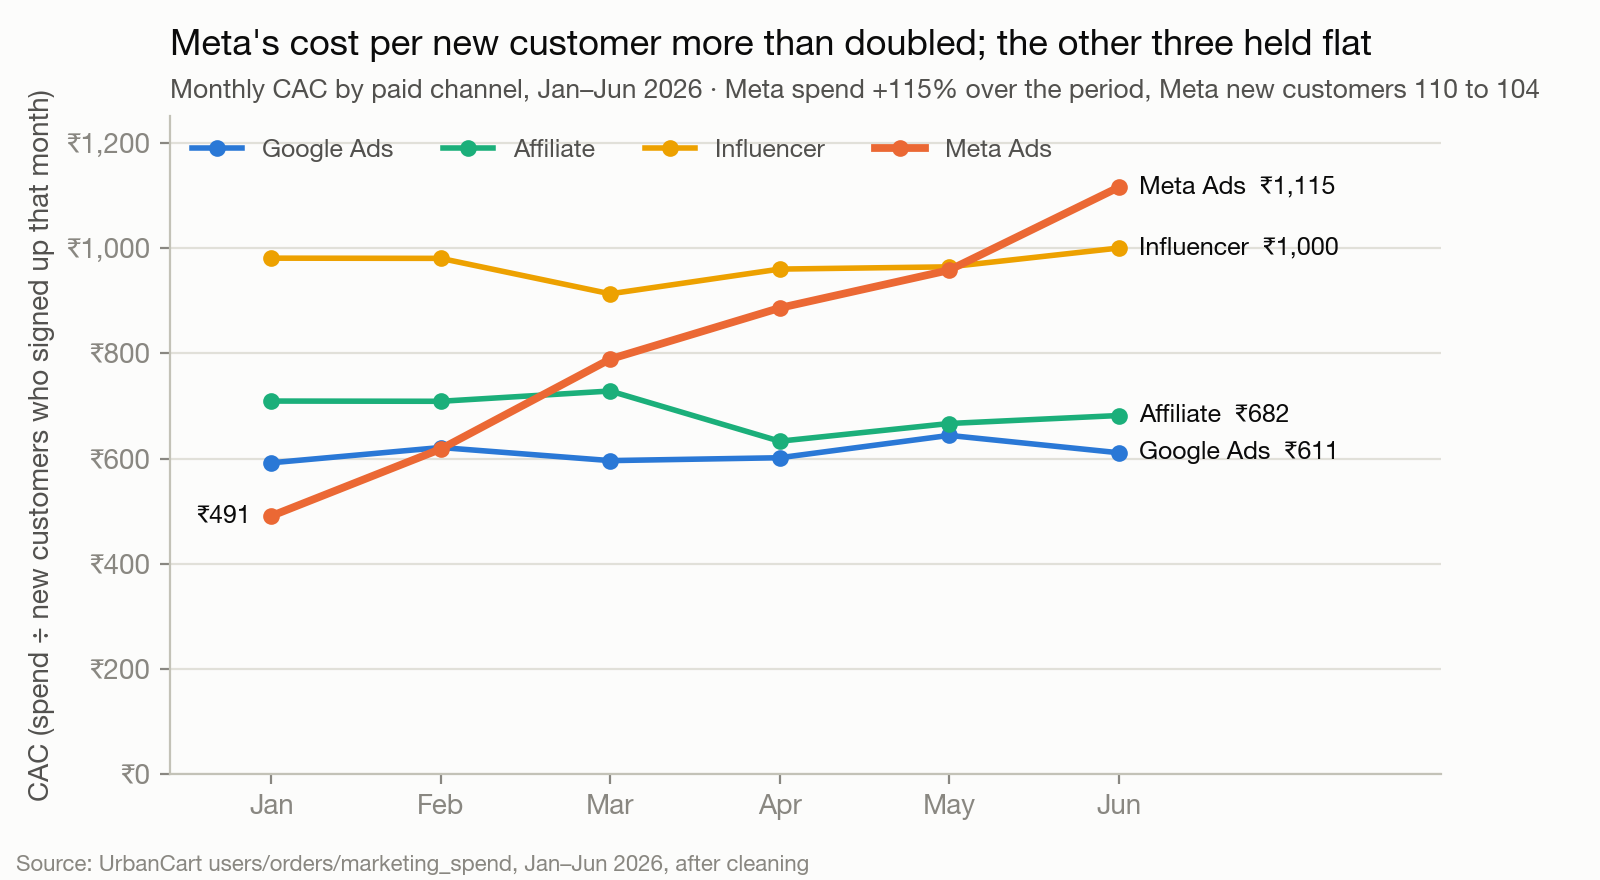

In [7]:
print(Q.Q5_MONTHLY_CAC)
show(res.q5_cac.rename_axis('channel'), money=list(res.q5_cac.columns), index=True)
show(res.q5_change[['channel', 'cac_jan', 'cac_jun', 'abs_change', 'pct_change', 'spend_pct_change']], money=['cac_jan', 'cac_jun', 'abs_change'], pct=['pct_change', 'spend_pct_change'])
display(Image(filename=str(ROOT / 'Part1_Analysis' / 'charts' / 'meta_spend_vs_new_customers.png'), width=820))
display(Image(filename=str(ROOT / 'Part2_Memo' / 'charts' / '2_monthly_cac_trend.png'), width=820))

Cohort truncation check — repeat rate by signup month (June signups had at most 30 days to repeat):

In [8]:
show(res.repeat_by_month, pct=['repeat_rate_pct'])

,signup_month,customers,repeat_rate_pct
0,2026-01,456,55.5%
1,2026-02,432,57.4%
2,2026-03,401,53.6%
3,2026-04,481,54.3%
4,2026-05,463,43.8%
5,2026-06,370,5.9%


## 6. Sanity check — Google Ads CAC

Reconciliation of every customer into one bucket, hand arithmetic, an independent pandas-only recomputation, and a plausibility check.

In [9]:
print(Q.Q6_RECONCILIATION)
display(res.q6)
g = res.q2.set_index('channel').loc['Google Ads']
print(f"Hand arithmetic: {A.inr(g.spend_inr)} / {int(g.new_customers)} = {g.cac:.2f} -> {A.inr(g.cac)}")
print('pandas-only recomputation:', res.pandas_crosscheck)
assert abs(res.pandas_crosscheck['google_cac'] - g.cac) < 1e-9
show(res.conversion, pct=['conversion_pct'])


    -- Q6: every user with a delivered order must land in exactly one bucket
    SELECT 'total distinct customers (deduped orders)' AS bucket, COUNT(DISTINCT user_id) AS customers
    FROM orders WHERE status = 'delivered'
    UNION ALL
    SELECT CASE WHEN is_internal THEN 'internal / test accounts'
                WHEN is_unknown_channel THEN 'unknown channel'
                ELSE acquisition_channel END, COUNT(*)
    FROM customers GROUP BY 1
    ORDER BY 1


,bucket,customers
0,Affiliate,505
1,Google Ads,655
2,Influencer,307
3,Meta Ads,675
4,Organic,461
5,internal / test accounts,35
6,total distinct customers (deduped orders),2678
7,unknown channel,40


Hand arithmetic: ₹4,00,000 / 655 = 610.69 -> ₹611
pandas-only recomputation: {'google_customers': 655, 'google_spend': 400000.0, 'google_cac': 610.6870229007634, 'google_signups': 1100}


,channel,signups,customers,conversion_pct
0,Google Ads,1100,655,59.5%
1,Organic,828,461,55.7%
2,Meta Ads,1300,675,51.9%
3,Influencer,600,307,51.2%
4,Affiliate,1200,505,42.1%


## Supporting tables

,channel,orders,cancel_or_return_pct
0,Affiliate,913,40.2%
1,Meta Ads,1192,9.7%
2,Google Ads,1293,6.8%
3,Organic,892,6.3%
4,Influencer,822,5.7%


,channel,q1_spend,q2_spend,h1_spend
0,Meta Ads,"₹2,08,000","₹3,39,000","₹5,47,000"
1,Google Ads,"₹1,95,000","₹2,05,000","₹4,00,000"
2,Affiliate,"₹1,76,000","₹1,70,000","₹3,46,000"
3,Influencer,"₹1,43,000","₹1,54,000","₹2,97,000"


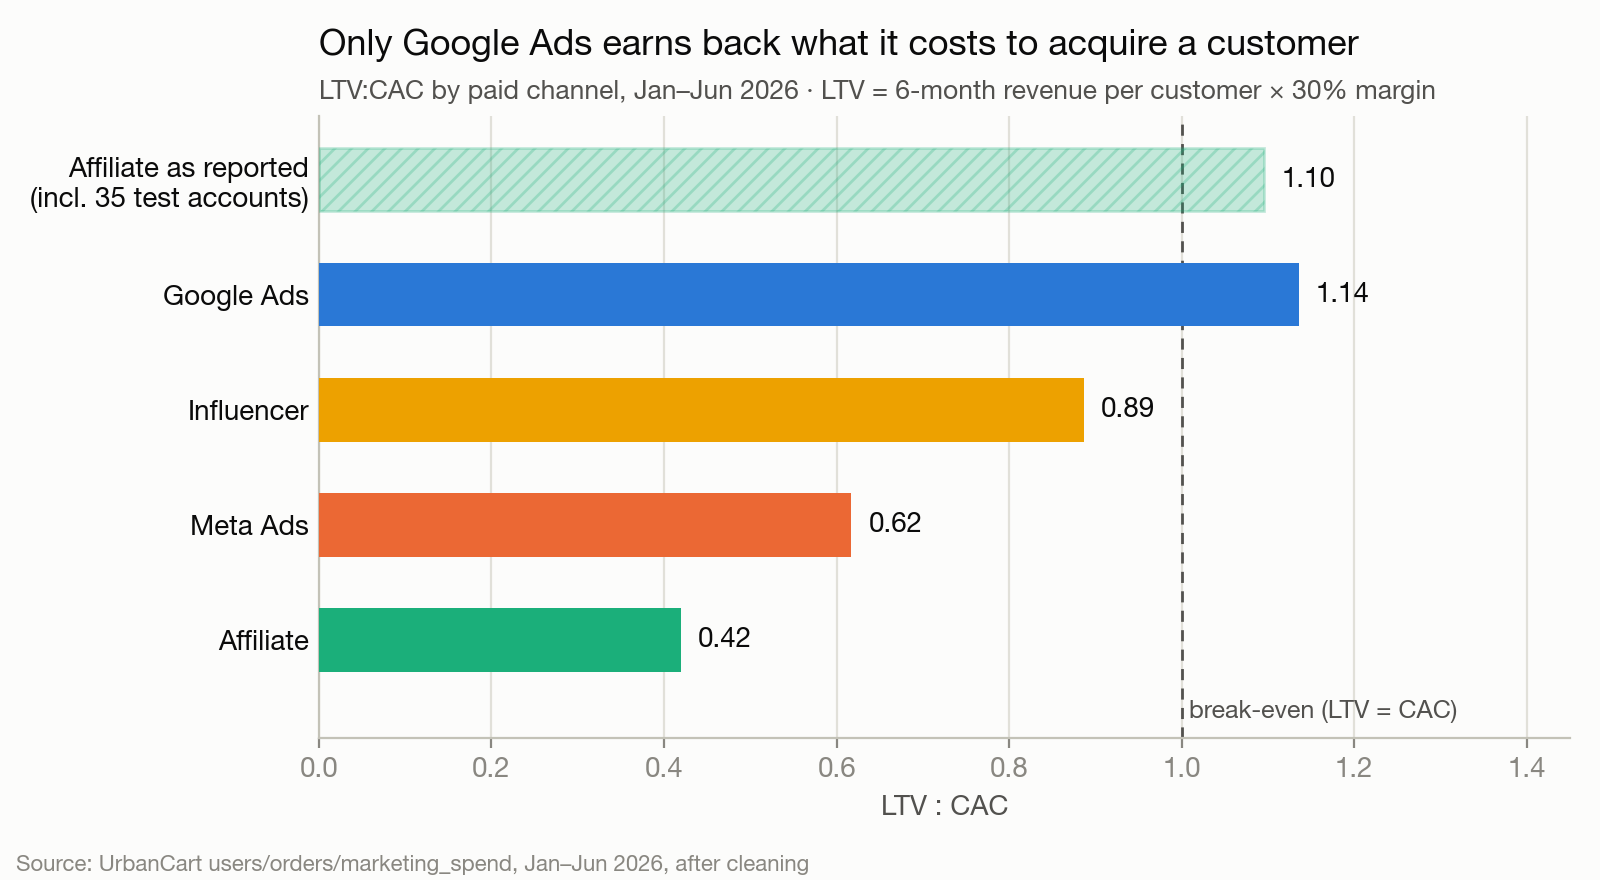

In [10]:
show(res.return_rate, pct=['cancel_or_return_pct'])
show(res.spend_by_quarter, money=['q1_spend', 'q2_spend', 'h1_spend'])
display(Image(filename=str(ROOT / 'Part2_Memo' / 'charts' / '1_ltv_cac_by_channel.png'), width=820))